In [37]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import nltk

nltk.download('wordnet')
nltk.download('omw-1.4')
nltk.download('stopwords')

from nltk.stem import WordNetLemmatizer
from wordcloud import WordCloud
from nltk.corpus import stopwords
lemmatizer = WordNetLemmatizer()

from datasets import load_dataset

[nltk_data] Downloading package wordnet to /home/pasali/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to /home/pasali/nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!
[nltk_data] Downloading package stopwords to /home/pasali/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


In [10]:
dataset = load_dataset("fancyzhx/ag_news")

# Pandas DataFrame'e dönüştür
df_train = dataset["train"].to_pandas()
df_test = dataset["test"].to_pandas()

# İlk kontrol
print("Train Shape:", df_train.shape)
print("Test Shape:", df_test.shape)

display(df_train.head())

Train Shape: (120000, 2)
Test Shape: (7600, 2)


,text,label
0,Wall St. Bears Claw Back Into the Black (Reute...,2
1,Carlyle Looks Toward Commercial Aerospace (Reu...,2
2,Oil and Economy Cloud Stocks' Outlook (Reuters...,2
3,Iraq Halts Oil Exports from Main Southern Pipe...,2
4,"Oil prices soar to all-time record, posing new...",2


In [11]:
# 1. Veri setinin genel bilgileri
df_train.info()

# 2. Eksik değer kontrolü
print("\nEksik Değerler:")
print(df_train.isnull().sum())

# 3. Benzersiz sınıflar
print("\nLabel Değerleri:")
print(df_train["label"].unique())

# 4. Sınıf dağılımı
print("\nSınıf Dağılımı:")
print(df_train["label"].value_counts().sort_index())

<class 'pandas.DataFrame'>
RangeIndex: 120000 entries, 0 to 119999
Data columns (total 2 columns):
 #   Column  Non-Null Count   Dtype
---  ------  --------------   -----
 0   text    120000 non-null  str  
 1   label   120000 non-null  int64
dtypes: int64(1), str(1)
memory usage: 28.9 MB

Eksik Değerler:
text     0
label    0
dtype: int64

Label Değerleri:
[2 3 1 0]

Sınıf Dağılımı:
label
0    30000
1    30000
2    30000
3    30000
Name: count, dtype: int64


In [13]:
class_names = dataset["train"].features["label"].names

label_mapping = dict(enumerate(class_names))

df_train["category"] = df_train["label"].map(label_mapping)


display(df_train[["text", "label", "category"]].head())

print("\nKategori dağılımı:")
print(df_train["category"].value_counts())

,text,label,category
0,Wall St. Bears Claw Back Into the Black (Reute...,2,Business
1,Carlyle Looks Toward Commercial Aerospace (Reu...,2,Business
2,Oil and Economy Cloud Stocks' Outlook (Reuters...,2,Business
3,Iraq Halts Oil Exports from Main Southern Pipe...,2,Business
4,"Oil prices soar to all-time record, posing new...",2,Business



Kategori dağılımı:
category
Business    30000
Sci/Tech    30000
Sports      30000
World       30000
Name: count, dtype: int64


In [14]:
# Her kategoriden 3 haber görüntüle
for category in class_names:

    print(f"\n{'=' * 60}")
    print(f"KATEGORİ: {category}")
    print("=" * 60)
    
    sample_news = df_train.loc[
        df_train["category"] == category, "text"
    ].head(3)

    for i, news in enumerate(sample_news, start=1):
        print(f"\nHaber {i}:")
        print(news)


KATEGORİ: World

Haber 1:
Venezuelans Vote Early in Referendum on Chavez Rule (Reuters) Reuters - Venezuelans turned out early\and in large numbers on Sunday to vote in a historic referendum\that will either remove left-wing President Hugo Chavez from\office or give him a new mandate to govern for the next two\years.

Haber 2:
S.Koreans Clash with Police on Iraq Troop Dispatch (Reuters) Reuters - South Korean police used water cannon in\central Seoul Sunday to disperse at least 7,000 protesters\urging the government to reverse a controversial decision to\send more troops to Iraq.

Haber 3:
Palestinians in Israeli Jails Start Hunger Strike (Reuters) Reuters - Thousands of Palestinian\prisoners in Israeli jails began a hunger strike for better\conditions Sunday, but Israel's security minister said he\didn't care if they starved to death.

KATEGORİ: Sports

Haber 1:
Phelps, Thorpe Advance in 200 Freestyle (AP) AP - Michael Phelps took care of qualifying for the Olympic 200-meter freestyl

In [15]:
# Her kategoriden 1000 haber
sample_df = (
    df_train
    .groupby("label", group_keys=False)
    .sample(n=1000, random_state=42)
)


print(sample_df.shape)

print(sample_df["label"].value_counts())

(4000, 3)
label
0    1000
1    1000
2    1000
3    1000
Name: count, dtype: int64


In [22]:
print(sample_df["text"].isnull().sum())

# Tamamen boş metin
print((sample_df["text"] == "").sum())

# Yalnızca boşluklardan oluşan metin
print((sample_df["text"].str.strip() == "").sum())

0
0
0


In [26]:
duplicates = sample_df["text"].duplicated(keep=False)

# Tekrarlanan metne ait satır sayısı
print("Duplicate sayısı:", duplicates.sum())

# Tekrarlanan kayıtları görüntüle
display(sample_df[duplicates])

Duplicate sayısı: 0


,text,label,category


In [27]:
sample_df["label"].value_counts(normalize=True)

label
0    0.25
1    0.25
2    0.25
3    0.25
Name: proportion, dtype: float64

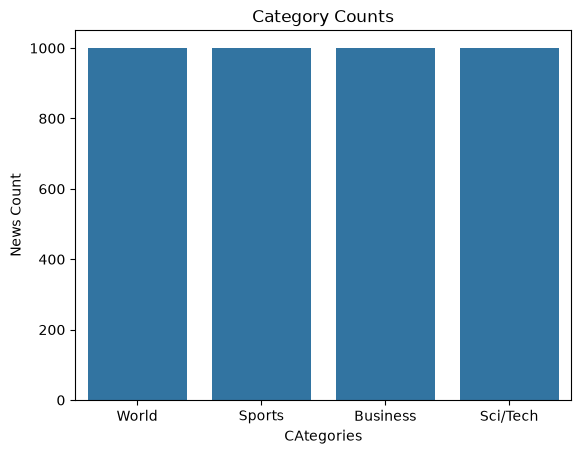

In [34]:

sns.countplot(data=sample_df , x="category")
plt.xlabel("CAtegories")
plt.title("Category Counts")
plt.ylabel("News Count")
plt.show()

In [38]:
def clean_text(text):
    # Replace missing values with empty strings
    text = text.fillna("")

    # Normalize casing
    text = text.str.lower()

    # Remove punctuation
    text = text.str.replace(r'[^\w\s]', '', regex=True)

    # Remove numbers
    text = text.str.replace(r'\d+', '', regex=True)

    # Normalize whitespace
    text = text.str.replace(r'\s+', ' ', regex=True).str.strip()

    # Remove English stopwords
    sw = set(stopwords.words("english"))
    text = text.apply(
        lambda x: " ".join(
            word for word in x.split()
            if word not in sw
        )
    )

    # Remove words that occur only once in the corpus
    temp_df = pd.Series(" ".join(text).split()).value_counts()
    drops = temp_df[temp_df <= 1].index
    text = text.apply(
        lambda x: " ".join(
            word for word in x.split()
            if word not in drops
        )
    )

    # Lemmatize tokens
    text = text.apply(
        lambda x: " ".join(
            lemmatizer.lemmatize(word)
            for word in x.split()
        )
    )

    return text


sample_df["text"] = clean_text(sample_df["text"])

In [39]:
sample_df["word_count"] = (
    sample_df["text"].str.split().str.len()
)

sample_df.head()

,text,label,category,word_count
8897,explosion rock baghdad neighborhood baghdad ir...,0,World,27
88708,bbc reporter log bbc record event middle east ...,0,World,16
92698,israel welcome rice palestinian wary israel tu...,0,World,26
99489,medical journal call new drug watchdog medical...,0,World,19
10525,militant relative iraqi militant kidnapped two...,0,World,22


In [45]:
sample_df["word_count"].describe(
    percentiles=[0.10, 0.20, 0.35, 0.50, 0.65, 0.75, 0.85, 0.90, 0.95, 0.99]
)

count    4000.000000
mean       22.769500
std         6.133088
min         2.000000
10%        16.000000
20%        18.000000
35%        20.000000
50%        22.000000
65%        24.000000
75%        26.000000
85%        28.000000
90%        30.000000
95%        32.000000
99%        41.000000
max        76.000000
Name: word_count, dtype: float64

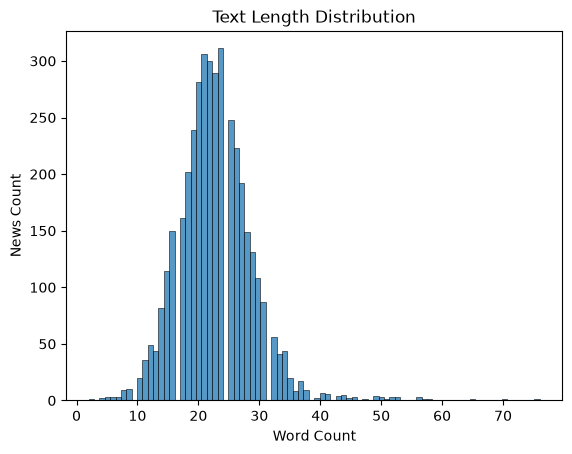

In [47]:
sns.histplot(data=sample_df , x="word_count")
plt.title("Text Length Distribution")
plt.xlabel("Word Count")
plt.ylabel("News Count")
plt.show()

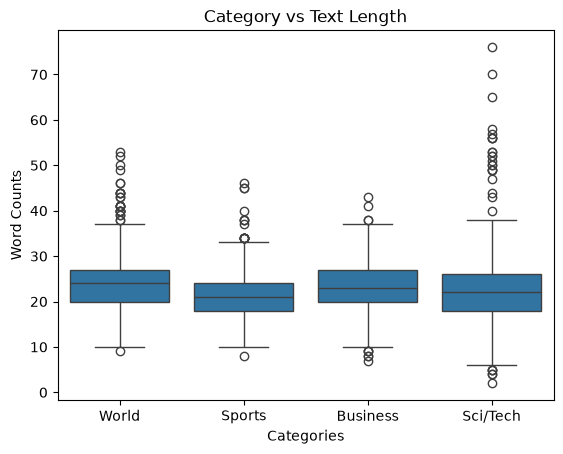

In [48]:
sns.boxplot(data=sample_df , x="category" , y="word_count")
plt.title("Category vs Text Length")
plt.xlabel("Categories")
plt.ylabel("Word Counts")
plt.show()